## Import

In [1]:
import pandas as pd
import numpy as np
import json
import joblib

from pathlib import Path

from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

## Load train dan test

In [2]:
TRAIN_PATH = Path("../data/processed/train.csv")
TEST_PATH = Path("../data/processed/test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Test :", test_df.shape)

display(train_df.head())

Train: (64000, 8)
Test : (16000, 8)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,1.000000,0.685714,0.0,delayed,caution,normal,caution,suspect
1,0.705882,0.857143,0.6,delayed,caution,caution,caution,suspect
2,0.294118,0.500000,0.4,caution,delayed,normal,caution,suspect
3,0.235294,0.400000,1.0,delayed,caution,advanced,caution,suspect
4,0.294118,0.585714,0.8,advanced,normal,caution,advanced,normal


## Tentukan fitur dan target

In [3]:
feature_columns = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

target_column = "dev_status"

categorical_columns = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (64000, 7)
y_train: (64000,)
X_test : (16000, 7)
y_test : (16000,)


## Validasi ulang target

In [4]:
print("Distribusi target TRAIN:")
display(y_train.value_counts())

print("\nDistribusi target TEST:")
display(y_test.value_counts())

Distribusi target TRAIN:


dev_status
suspect    51182
normal     12818
Name: count, dtype: int64


Distribusi target TEST:


dev_status
suspect    12796
normal      3204
Name: count, dtype: int64

## Parameter Baseline

In [5]:
baseline_params = {
    "learning_rate": 0.1,
    "depth": 6,
    "iterations": 200,
    "random_seed": 42
}

print("Parameter Baseline CatBoost:")
for parameter, value in baseline_params.items():
    print(f"{parameter}: {value}")

Parameter Baseline CatBoost:
learning_rate: 0.1
depth: 6
iterations: 200
random_seed: 42


## 5-Fold Cross-Validation

In [6]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train),
    start=1
):
    print(f"\n===== FOLD {fold} =====")

    X_fold_train = X_train.iloc[train_idx].copy()
    X_fold_val = X_train.iloc[val_idx].copy()

    y_fold_train = y_train.iloc[train_idx].copy()
    y_fold_val = y_train.iloc[val_idx].copy()

    model = CatBoostClassifier(
        learning_rate=0.1,
        depth=6,
        iterations=200,
        random_seed=42,
        boosting_type="Ordered",
        grow_policy="SymmetricTree",
        loss_function="Logloss",
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=categorical_columns
    )

    y_pred = model.predict(X_fold_val).ravel()

    accuracy = accuracy_score(y_fold_val, y_pred)

    precision = precision_score(
        y_fold_val,
        y_pred,
        pos_label="suspect",
        zero_division=0
    )

    recall = recall_score(
        y_fold_val,
        y_pred,
        pos_label="suspect",
        zero_division=0
    )

    f1 = f1_score(
        y_fold_val,
        y_pred,
        pos_label="suspect",
        zero_division=0
    )

    cv_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")


===== FOLD 1 =====
Accuracy : 0.9730
Precision: 0.9743
Recall   : 0.9924
F1-Score : 0.9833

===== FOLD 2 =====
Accuracy : 0.9725
Precision: 0.9748
Recall   : 0.9912
F1-Score : 0.9830

===== FOLD 3 =====
Accuracy : 0.9727
Precision: 0.9760
Recall   : 0.9902
F1-Score : 0.9831

===== FOLD 4 =====
Accuracy : 0.9727
Precision: 0.9747
Recall   : 0.9915
F1-Score : 0.9830

===== FOLD 5 =====
Accuracy : 0.9739
Precision: 0.9751
Recall   : 0.9927
F1-Score : 0.9838


## Ringkasan 5-Fold CV

In [7]:
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

cv_summary = cv_results_df.drop(columns=["fold"]).agg(
    ["mean", "std"]
)

display(cv_summary)

,fold,accuracy,precision,recall,f1
0,1,0.972969,0.974297,0.992381,0.983256
1,2,0.972500,0.974829,0.991208,0.982951
2,3,0.972734,0.976023,0.990231,0.983076
3,4,0.972656,0.974741,0.991501,0.983049
4,5,0.973906,0.975144,0.992673,0.983830


,accuracy,precision,recall,f1
mean,0.972953,0.975007,0.991599,0.983232
std,0.000559,0.000644,0.000975,0.000352


## Train Baseline Final

In [8]:
baseline_model = CatBoostClassifier(
    learning_rate=0.1,
    depth=6,
    iterations=200,
    random_seed=42,
    boosting_type="Ordered",
    grow_policy="SymmetricTree",
    loss_function="Logloss",
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

baseline_model.fit(
    X_train,
    y_train,
    cat_features=categorical_columns
)

print("✅ Baseline CatBoost berhasil dilatih menggunakan seluruh data TRAIN.")

✅ Baseline CatBoost berhasil dilatih menggunakan seluruh data TRAIN.


## Evaluasi final pada TEST

In [9]:
y_test_pred = baseline_model.predict(X_test).ravel()

accuracy_test = accuracy_score(y_test, y_test_pred)

precision_test = precision_score(
    y_test,
    y_test_pred,
    pos_label="suspect",
    zero_division=0
)

recall_test = recall_score(
    y_test,
    y_test_pred,
    pos_label="suspect",
    zero_division=0
)

f1_test = f1_score(
    y_test,
    y_test_pred,
    pos_label="suspect",
    zero_division=0
)

print("===== BASELINE CATBOOST — TEST =====")
print(f"Accuracy : {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall   : {recall_test:.4f}")
print(f"F1-Score : {f1_test:.4f}")

===== BASELINE CATBOOST — TEST =====
Accuracy : 0.9738
Precision: 0.9756
Recall   : 0.9920
F1-Score : 0.9837


## Classification Report

In [10]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["normal", "suspect"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      normal       0.97      0.90      0.93      3204
     suspect       0.98      0.99      0.98     12796

    accuracy                           0.97     16000
   macro avg       0.97      0.95      0.96     16000
weighted avg       0.97      0.97      0.97     16000



## Confusion Matrix

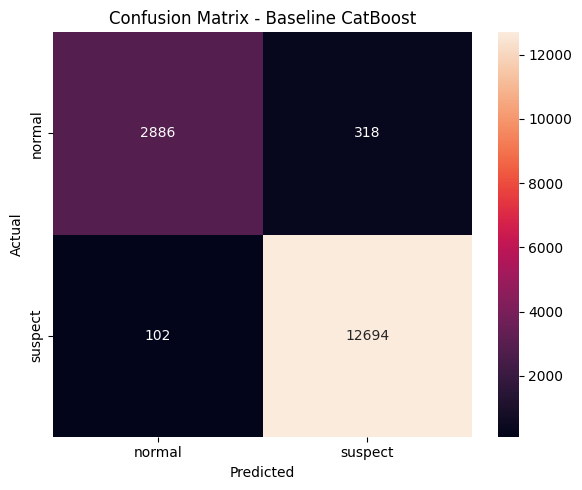

In [11]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["normal", "suspect"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["normal", "suspect"],
    yticklabels=["normal", "suspect"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Baseline CatBoost")

plt.tight_layout()
plt.show()

## Feature Importance

In [12]:
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": baseline_model.get_feature_importance()
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

,feature,importance
4,fine_motor_adaptive,27.412363
5,language,25.432747
3,gross_motor,23.442917
6,personal_social,22.612202
1,height,0.561995
0,weight,0.368232
2,age,0.169544


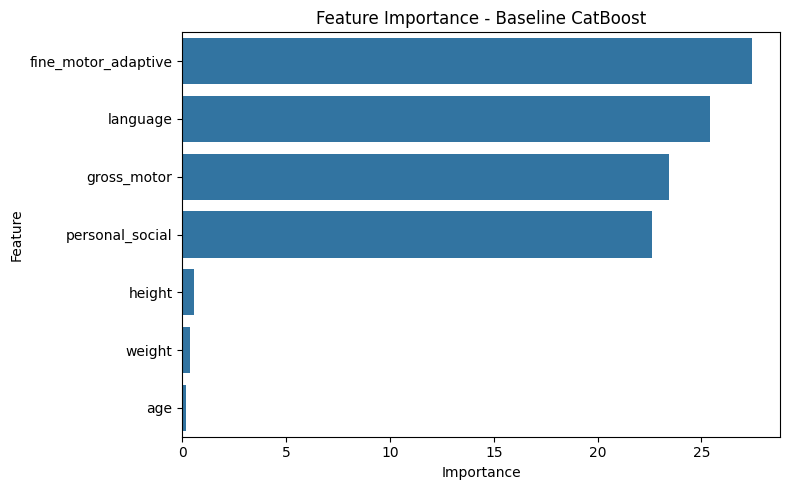

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title("Feature Importance - Baseline CatBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Simpan hasil evaluasi

In [14]:
OUTPUT_METRICS = Path("../outputs/metrics")
OUTPUT_FIGURES = Path("../outputs/figures")
MODEL_DIR = Path("../models/catboost")

OUTPUT_METRICS.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [15]:
baseline_metrics = {
    "model": "CatBoost Baseline",
    "learning_rate": 0.1,
    "depth": 6,
    "iterations": 200,
    "random_seed": 42,
    "cv_folds": 5,
    "cv_accuracy_mean": float(cv_results_df["accuracy"].mean()),
    "cv_accuracy_std": float(cv_results_df["accuracy"].std()),
    "cv_precision_mean": float(cv_results_df["precision"].mean()),
    "cv_precision_std": float(cv_results_df["precision"].std()),
    "cv_recall_mean": float(cv_results_df["recall"].mean()),
    "cv_recall_std": float(cv_results_df["recall"].std()),
    "cv_f1_mean": float(cv_results_df["f1"].mean()),
    "cv_f1_std": float(cv_results_df["f1"].std()),
    "test_accuracy": float(accuracy_test),
    "test_precision": float(precision_test),
    "test_recall": float(recall_test),
    "test_f1": float(f1_test)
}

with open(
    OUTPUT_METRICS / "baseline_catboost_metrics.json",
    "w"
) as f:
    json.dump(baseline_metrics, f, indent=4)

cv_results_df.to_csv(
    OUTPUT_METRICS / "baseline_catboost_cv.csv",
    index=False
)

feature_importance.to_csv(
    OUTPUT_METRICS / "baseline_catboost_feature_importance.csv",
    index=False
)

print("✅ Semua metrics berhasil disimpan.")

✅ Semua metrics berhasil disimpan.


## Simpan model

In [16]:
MODEL_PATH = MODEL_DIR / "baseline_catboost.cbm"

baseline_model.save_model(MODEL_PATH)

print(f"✅ Model disimpan di: {MODEL_PATH}")

✅ Model disimpan di: ..\models\catboost\baseline_catboost.cbm


## Final check

In [17]:
print("=" * 60)
print("CHECKPOINT 3.5 — BASELINE CATBOOST")
print("=" * 60)

print("\nParameter:")
print("Learning Rate :", 0.1)
print("Depth         :", 6)
print("Iterations    :", 200)
print("Random Seed   :", 42)

print("\n5-Fold CV:")
print(f"Accuracy  : {cv_results_df['accuracy'].mean():.4f} ± {cv_results_df['accuracy'].std():.4f}")
print(f"Precision : {cv_results_df['precision'].mean():.4f} ± {cv_results_df['precision'].std():.4f}")
print(f"Recall    : {cv_results_df['recall'].mean():.4f} ± {cv_results_df['recall'].std():.4f}")
print(f"F1-Score  : {cv_results_df['f1'].mean():.4f} ± {cv_results_df['f1'].std():.4f}")

print("\nFINAL TEST:")
print(f"Accuracy  : {accuracy_test:.4f}")
print(f"Precision : {precision_test:.4f}")
print(f"Recall    : {recall_test:.4f}")
print(f"F1-Score  : {f1_test:.4f}")

print("\nStatus:")
print("✅ Baseline selesai.")
print("✅ Test set hanya digunakan pada evaluasi final.")
print("✅ dev_status tidak digunakan sebagai fitur.")
print("✅ KGE belum digunakan.")
print("✅ Hyperparameter belum dituning.")

CHECKPOINT 3.5 — BASELINE CATBOOST

Parameter:
Learning Rate : 0.1
Depth         : 6
Iterations    : 200
Random Seed   : 42

5-Fold CV:
Accuracy  : 0.9730 ± 0.0006
Precision : 0.9750 ± 0.0006
Recall    : 0.9916 ± 0.0010
F1-Score  : 0.9832 ± 0.0004

FINAL TEST:
Accuracy  : 0.9738
Precision : 0.9756
Recall    : 0.9920
F1-Score  : 0.9837

Status:
✅ Baseline selesai.
✅ Test set hanya digunakan pada evaluasi final.
✅ dev_status tidak digunakan sebagai fitur.
✅ KGE belum digunakan.
✅ Hyperparameter belum dituning.


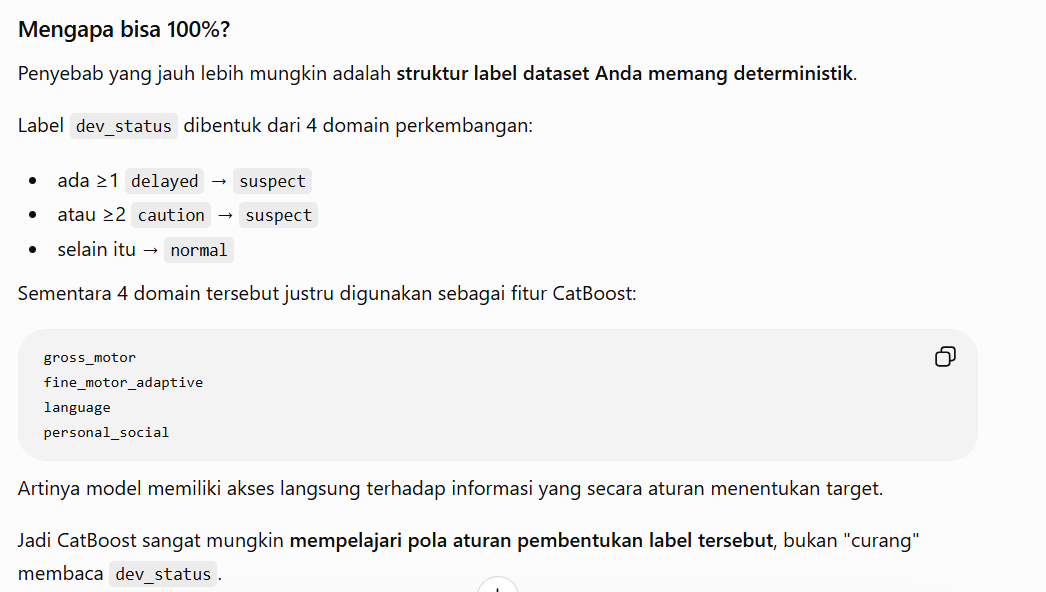

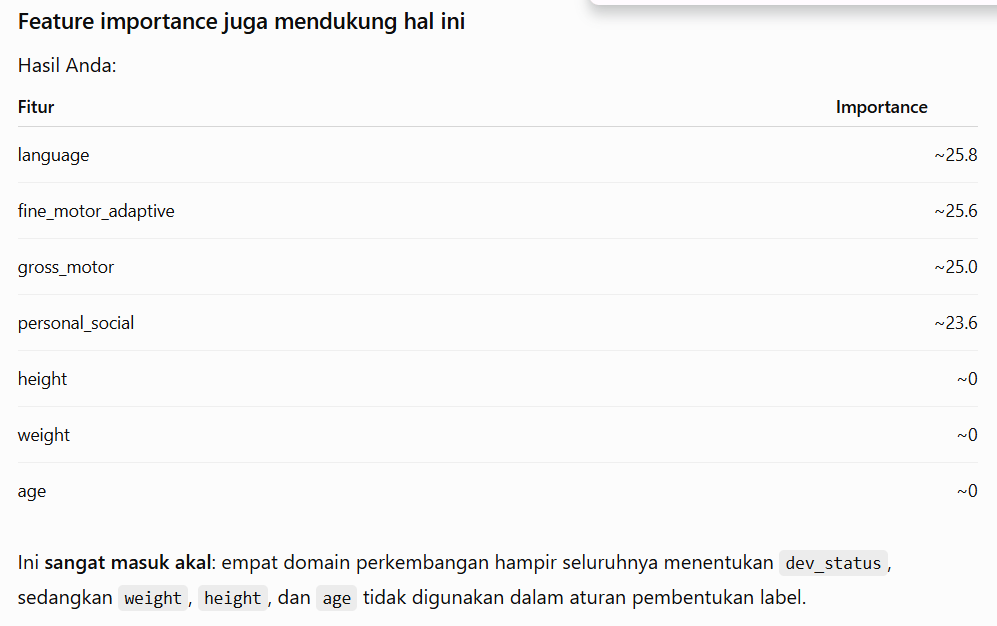